# Ball stationary at a restart location (clause c)

Tests clause c of the draft dead-ball rule: *ball visible and stationary for ≥ T s at a restart location → dead*. Script: `ball_stationary.py`.

> **Run this notebook on the VM only.** Once run, its outputs are derived from the competition match. Before a copy with outputs leaves the VM, clear it:
> `jupyter nbconvert --clear-output --inplace eda_ball_stationary.ipynb`.

The script commands are **comments**: run them in a VM terminal from the team-repo root (or remove the `#` and prefix `!`). The cells below each command only read the summary CSVs the scripts wrote under `EDA_OUT` (default `~/eda_out`); none of them reads match data. Charts share one look from `plot_helpers.py`: one colour per set-piece `Type`, dark ink for observed values, a light grey band (p5–p95) with a dashed mean for the circular-shift null, and grey 'n < 5' stubs where there is too little to plot.

Definitions, defaults and CSV schemas: `eda/README.md`, section "Analyses".

In [1]:
import os
import sys
from pathlib import Path

# The eda/ folder (Jupyter's working directory when the notebook is opened from there) and the
# script outputs. Override with EDA_DIR / EDA_OUT in the shell that starts Jupyter.
EDA_DIR = Path(os.environ.get("EDA_DIR", Path.cwd()))
EDA_OUT = Path(os.environ.get("EDA_OUT", Path.home() / "eda_out"))
sys.path.insert(0, str(EDA_DIR))

print("eda folder:", EDA_DIR, "(plot_helpers.py found)" if (EDA_DIR / "plot_helpers.py").is_file()
      else "(plot_helpers.py MISSING: set EDA_DIR)")
print("EDA_OUT   :", EDA_OUT)

eda folder: /home/robli-macbook-air-2026/more-than-a-hack/eda (plot_helpers.py found)
EDA_OUT   : /home/robli-macbook-air-2026/eda_out


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import plot_helpers as ph

ph.style()

In [3]:
CSV = "ball_stationary_summary.csv"
bs = ph.load_summary(EDA_OUT, "ball_stationary", CSV)
SENS = {"still < 0.3 m/s": ph.load_summary(EDA_OUT, "ball_stationary_still03", CSV),
        "mark tolerance 2 m": ph.load_summary(EDA_OUT, "ball_stationary_tol2", CSV)}

mins = ph.pick(bs, "params", "all", None, "min_still")
MAIN = float(mins[mins.bin == "main"].value.iloc[0])
MINS = sorted(mins.value.astype(float))
W = ph.get(bs, "params", "all", "", "link_window")
K = ph.null_k(bs)
HAS_TAGS = len(ph.pick(bs, "link")) > 0
LOCS = ["centre_spot", "penalty_spot", "corner_arc", "goal_area", "touchline_band", "elsewhere"]
LOC_LABEL = {l: l.replace("_", " ") for l in LOCS}


def sc(m, loc, df=None):
    return "s{:g}:{}".format(m, loc)


print("main minimum {:g} s, all {}, link window {:g} s, null K = {}, tags: {}".format(
    MAIN, MINS, W, K, HAS_TAGS))

main minimum 1 s, all [0.5, 1.0, 2.0], link window 5 s, null K = 1000, tags: True


## 1. Where does the ball sit still, and how much of the match does that cover?

In [4]:
# cd ~/more-than-a-hack
# PYTHONPATH="$PWD" python3 eda/ball_stationary.py "$HOME/eda_out/ball_stationary"
# PYTHONPATH="$PWD" python3 eda/ball_stationary.py "$HOME/eda_out/ball_stationary_still03" --still-ms 0.3
# PYTHONPATH="$PWD" python3 eda/ball_stationary.py "$HOME/eda_out/ball_stationary_tol2" --spot-tol-m 2

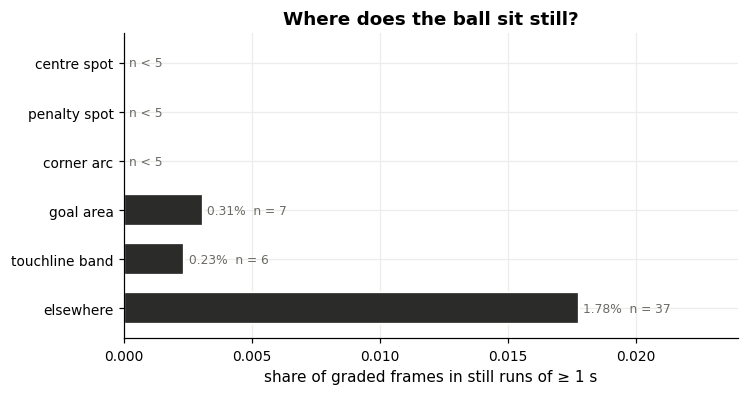

,"runs, ≥ 0.5 s","runs, ≥ 1 s","runs, ≥ 2 s","runs, still < 0.3 m/s","runs, mark tolerance 2 m"
centre spot,0,0,0,0,1
penalty spot,1,0,0,0,0
corner arc,0,0,0,0,0
goal area,9,7,4,6,7
touchline band,9,6,4,2,6
elsewhere,78,37,18,25,36
all,97,50,26,33,50


In [5]:
share = [ph.get(bs, "location", sc(MAIN, l), "", "share") for l in LOCS]
n = [ph.get(bs, "location", sc(MAIN, l), "", "n_runs") for l in LOCS]

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ph.bars_with_n(ax, [LOC_LABEL[l] for l in LOCS], share, n, horizontal=True, fmt="{:.2%}")
ax.set_xlabel("share of graded frames in still runs of ≥ {:g} s".format(MAIN))
ax.set_title("Where does the ball sit still?")
plt.show()

table = {"runs, ≥ {:g} s".format(m): [int(ph.get(bs, "location", sc(m, l), "", "n_runs"))
                                       for l in LOCS + ["all"]] for m in MINS}
for label, df in SENS.items():
    if df is not None:
        table["runs, {}".format(label)] = [int(ph.get(df, "location", sc(MAIN, l), "", "n_runs"))
                                           for l in LOCS + ["all"]]
display(pd.DataFrame(table, index=[LOC_LABEL[l] for l in LOCS] + ["all"]))

**How to read this.** Bar length is the share of graded frames inside still runs (at least the main minimum length) placed at each mark; the label adds the share and the number of runs. Grey stubs have fewer than 5 runs. The table shows the run counts at the other minimum lengths and in the sensitivity runs. Clause c needs runs at the restart marks (corner arc, goal area, touchline band, centre spot, penalty spot). If nearly everything is "elsewhere" or the total share is tiny, the tracker rarely sees a waiting ball and clause c can only add a little.

**Takeaway.** _to fill in after running_

## 2. How long does the ball stay still at each mark?

In [6]:
# (same run as section 1)

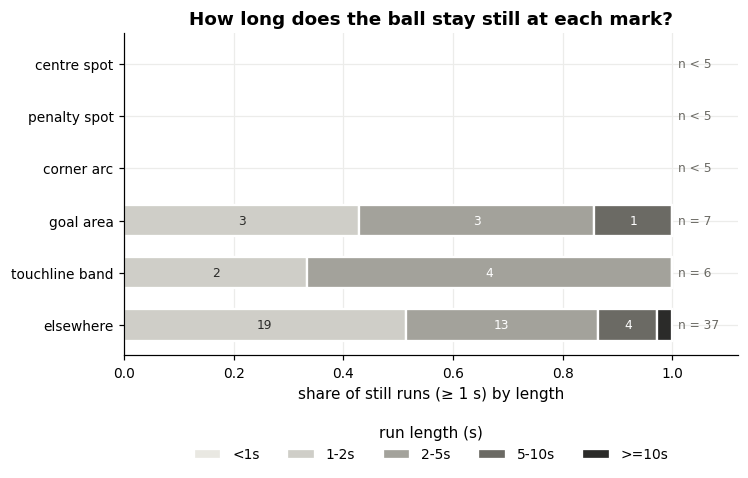

In [7]:
BINS = ["<1s", "1-2s", "2-5s", "5-10s", ">=10s"]
colours = dict(zip(BINS, ph.GREYS[::-1]))        # longer = darker
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for i, l in enumerate(LOCS):
    counts = [ph.get(bs, "runs", sc(MAIN, l), b, "n_runs") for b in BINS]
    total = sum(counts)
    left = 0.0
    for b, k in zip(BINS, counts):
        s = k / total if total >= ph.MIN_N else 0.0
        ax.barh(i, s, left=left, height=0.6, color=colours[b], edgecolor="white", lw=1.5,
                label=b if i == 0 else None)
        if s >= 0.1:
            ax.text(left + s / 2, i, "{:.0f}".format(k), ha="center", va="center", fontsize=8,
                    color="white" if b in BINS[2:] else ph.REAL)
        left += s
    ax.text(1.01, i, "n < 5" if total < ph.MIN_N else "n = {:,}".format(int(total)),
            va="center", fontsize=8, color=ph.INK_2)
ax.set_yticks(range(len(LOCS)), [LOC_LABEL[l] for l in LOCS])
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xlabel("share of still runs (≥ {:g} s) by length".format(MAIN))
ax.set_title("How long does the ball stay still at each mark?")
ax.legend(title="run length (s)", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5)
plt.show()

**How to read this.** Each row splits the still runs at one mark by length (darker = longer); segment labels are run counts. A restart typically holds the ball still for a few seconds (throw-ins less, corners and free kicks more). Long runs at the marks support a T of a few seconds for clause c; if runs at the marks are mostly 1–2 s, T must stay short.

**Takeaway.** _to fill in after running_

## 3. Does a still ball at a mark end near a set-piece start more often than chance?

In [8]:
# (same run as section 1)

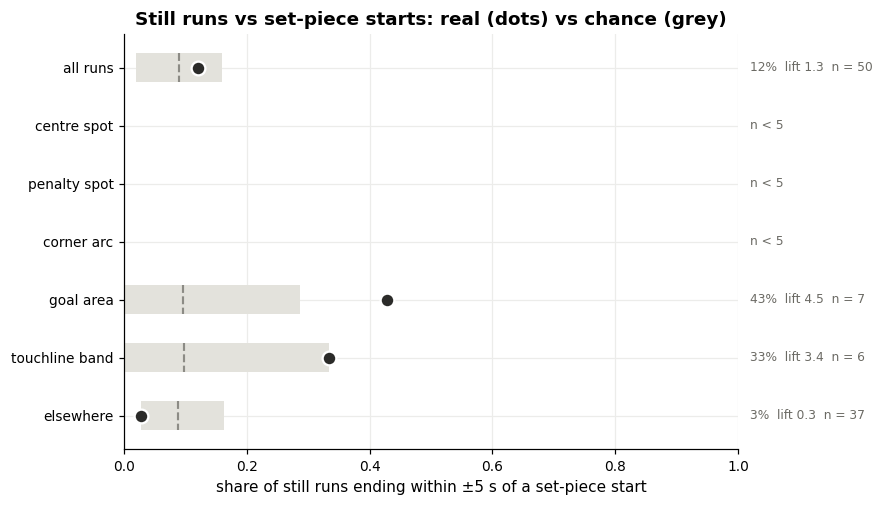

,runs,linked,share,null mean,lift,p
location,,,,,,
all,50,6,0.120,0.090,1.334,p = 0.307
centre spot,0,0,NaN,NaN,NaN,-
penalty spot,0,0,NaN,NaN,NaN,-
corner arc,0,0,NaN,NaN,NaN,-
goal area,7,3,0.429,0.096,4.458,p = 0.039
touchline band,6,2,0.333,0.098,3.419,p = 0.129
elsewhere,37,1,0.027,0.088,0.309,p = 0.967


In [9]:
if not HAS_TAGS:
    print("no Smart Tagging file in this run: section skipped")
else:
    SP = "code:SET PIECES"
    cats = ["all"] + LOCS
    fig, ax = plt.subplots(figsize=(7.2, 0.5 * len(cats) + 1.4))
    rows = []
    for i, l in enumerate(cats):
        def v(metric):
            return ph.get(bs, "link", sc(MAIN, l), SP, metric)
        if np.isfinite(v("null_p5")):
            ph.null_interval(ax, i, v("null_p5"), v("null_p95"), v("null_mean"))
        ok = v("n_runs") >= ph.MIN_N
        if ok:
            ax.plot(v("real_share"), i, "o", ms=9, color=ph.REAL, mec="white", mew=1.5, zorder=3)
        ax.text(1.02, i, "{:.0%}  lift {:.1f}  n = {:,}".format(v("real_share"), v("lift"),
                                                               int(v("n_runs")))
                if ok else "n < 5", va="center", fontsize=8, color=ph.INK_2,
                transform=ax.get_yaxis_transform())
        rows.append({"location": "all" if l == "all" else LOC_LABEL[l], "runs": int(v("n_runs")),
                     "linked": int(v("real_count")), "share": v("real_share"),
                     "null mean": v("null_mean"), "lift": v("lift"),
                     "p": ph.fmt_p(v("p_emp"), K)})
    ax.set_yticks(range(len(cats)), ["all runs"] + [LOC_LABEL[l] for l in LOCS])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of still runs ending within ±{:g} s of a set-piece start".format(W))
    ax.set_title("Still runs vs set-piece starts: real (dots) vs chance (grey)")
    plt.show()
    display(pd.DataFrame(rows).set_index("location").round(3))

**How to read this.** For each location, the dot is the share of still runs whose last frame is within ±W s of any set-piece start; the grey band is the same share under circularly shifted tags (p5–p95, dashed mean). Locations with fewer than 5 runs show no dot. Dots far right of their band at the restart marks support clause c. If "elsewhere" links as strongly as the marks, stillness alone carries the signal and the location condition can be relaxed; if the marks sit inside their bands, clause c adds little.

**Takeaway.** _to fill in after running_

## 4. Which restart follows a still ball at each mark?

In [10]:
# (same run as section 1)

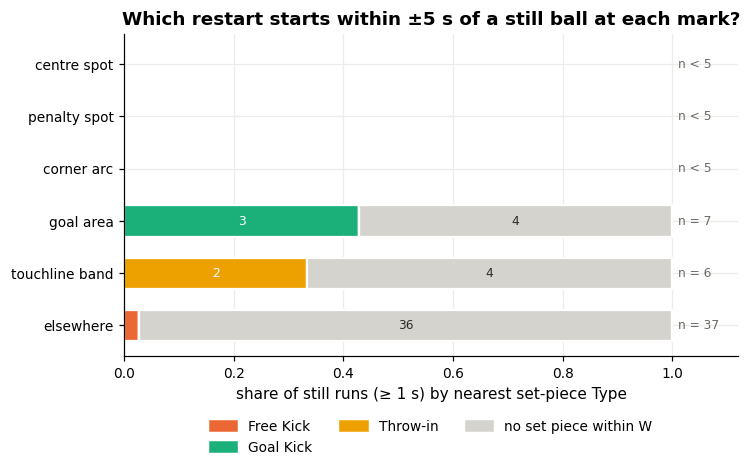

,Free Kick,Goal Kick,Throw-in,none
location,,,,
centre spot,0,0,0,0
penalty spot,0,0,0,0
corner arc,0,0,0,0
goal area,0,3,0,4
touchline band,0,0,2,4
elsewhere,1,0,0,36


In [11]:
if not HAS_TAGS:
    print("no Smart Tagging file in this run: section skipped")
else:
    ct = ph.pick(bs, "crosstab", None, None, "n_runs")
    types = ph.sort_groups([t for t in ct.bin.unique() if t not in ("none", "(no Type)")])
    types += [t for t in ("(no Type)", "none") if t in set(ct.bin)]
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    table = {}
    for i, l in enumerate(LOCS):
        counts = {t: ph.get(bs, "crosstab", sc(MAIN, l), t, "n_runs") for t in types}
        counts = {t: (0 if not np.isfinite(k) else int(k)) for t, k in counts.items()}
        table[LOC_LABEL[l]] = counts
        total = sum(counts.values())
        left = 0.0
        for t in types:
            s = counts[t] / total if total >= ph.MIN_N else 0.0
            ax.barh(i, s, left=left, height=0.6, color=ph.type_colour(t), edgecolor="white", lw=1.5)
            if s >= 0.1:
                ax.text(left + s / 2, i, str(counts[t]), ha="center", va="center", fontsize=8,
                        color="white" if t not in ("none", "(no Type)") else ph.REAL)
            left += s
        ax.text(1.01, i, "n < 5" if total < ph.MIN_N else "n = {:,}".format(total), va="center",
                fontsize=8, color=ph.INK_2)
    ax.set_yticks(range(len(LOCS)), [LOC_LABEL[l] for l in LOCS])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("share of still runs (≥ {:g} s) by nearest set-piece Type".format(MAIN))
    ax.set_title("Which restart starts within ±{:g} s of a still ball at each mark?".format(W))
    ph.type_legend(ax, [t for t in types if t not in ("none", "(no Type)")], extra=[("no set piece within W", ph.NO_TYPE)],
                   below=-0.16, ncol=3)
    plt.show()
    display(pd.DataFrame(table).T.rename_axis("location"))

**How to read this.** Each row splits the still runs at one mark by the `Type` of the nearest set-piece start within ±W s (same colours in every notebook; light grey = none). The football expectation: corner arc → corner kick, goal area → goal kick, touchline band → throw-in, centre spot → kick-off; free kicks anywhere. A clean diagonal means clause c can also say *which* restart is coming. The penalty spot has no tag type, so it should be grey.

**Takeaway.** _to fill in after running_

## 5. Does the ball sit on the centre spot, with each team in its own half, at every kick-off?

In [12]:
# (same run as section 1; needs the ATD metadata, which the default run reads)

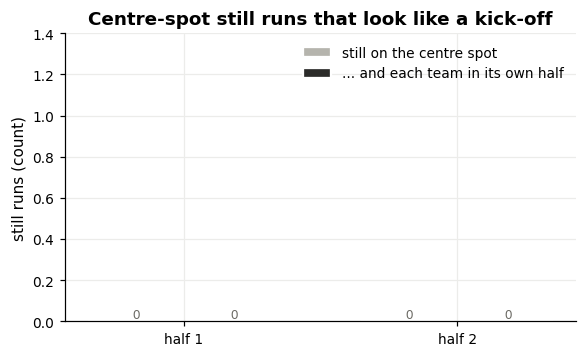

In [13]:
ko = ph.pick(bs, "kickoff", sc(MAIN, "centre_spot"))
if not len(ko):
    print("no kick-off rows (run without ATD metadata): section skipped")
else:
    halves = sorted(ko.bin.unique())
    centre = [ph.get(bs, "kickoff", sc(MAIN, "centre_spot"), h, "centre_runs") for h in halves]
    kick = [ph.get(bs, "kickoff", sc(MAIN, "centre_spot"), h, "kickoff_runs") for h in halves]
    fig, ax = plt.subplots(figsize=(6.0, 3.4))
    x = np.arange(len(halves))
    ax.bar(x - 0.18, centre, width=0.34, color=ph.INK_3, edgecolor="white", lw=1.5,
           label="still on the centre spot")
    ax.bar(x + 0.18, kick, width=0.34, color=ph.REAL, edgecolor="white", lw=1.5,
           label="... and each team in its own half")
    for i, (c, k) in enumerate(zip(centre, kick)):
        ax.text(i - 0.18, c, " {:.0f}".format(c), ha="center", va="bottom", fontsize=8, color=ph.INK_2)
        ax.text(i + 0.18, k, " {:.0f}".format(k), ha="center", va="bottom", fontsize=8, color=ph.INK_2)
    ax.set_xticks(x, halves)
    ax.set_ylim(0, max(max(centre), 1) * 1.4)
    ax.set_ylabel("still runs (count)")
    ax.set_title("Centre-spot still runs that look like a kick-off")
    ax.legend(loc="upper right")
    plt.show()

**How to read this.** Per half, light bars count still runs on the centre spot and dark bars those whose last frame also has every home player on one side of halfway and every away player on the other. Each half should have one kick-off, plus one after every goal. Fewer dark runs than kick-offs means the ball is not tracked (or not still) at kick-off, so kick-offs need another signal; more means the centre spot sees other still balls (e.g. a free kick there).

**Takeaway for 5:** zero centre-spot still runs is a detector failure, not the football. The match has at least
five graded kick-offs (one start-of-half, four after goals). The ball-missing profile around kick-off tags
(`eda_ball_missing.ipynb`, Section Z, last cell) shows two different causes:

- **Start of half (n = 1):** the ball is visible from about −3 s before the tag start onwards, so a placed
  ball *was* on screen and the detector still missed it. Likely causes: the per-frame stillness test can't
  fire because of ball-position jitter, or the centre-spot radius/coordinates are off.
  → Switch to windowed displacement (< 0.5 m over 1 s) and sweep the radius (1, 2, 3 m).
- **After a goal (n = 4):** the ball is missing in all four until about +2 s after the tag start, so it is
  never visible while placed. No stillness test can find these.
  → Detect kick-offs from the player formation instead: every player in their own half, opponents outside
  the centre circle (9.15 m), a kicking-team player at the spot. This also gives the kicking team.

**Tag start ≠ kick.** After goals, the ball reappears 2–3 s after the tag start. End `D` when the ball
reappears or the formation breaks, not at the tag start (1 s late costs about a third of a possession's
`spellF1`).

n = 5 is too small to tune on: set formation thresholds from the laws of the game and the reference set.